# CHELATE

This notebook demonstrates how to run CHELATE on a set of docking poses. We use the PLINDER system `4hev__1__1.A__1.C_1.D`, a zinc metalloprotein, and cross-docked Vina poses as an example.

CHELATE is installable as a standalone package, so nothing here depends on the rest of this repository:

```bash
pip install -e ../..          # from this directory
```

The structure renders below additionally need PyMOL (`conda install -c conda-forge pymol-open-source`), and the comparison against the crystal pose needs the optional evaluation extra (`pip install -e "../..[eval]"`). Neither is required to run CHELATE itself.

In [1]:
from chelate import predict_poses

example_dir = "4hev__1__1.A__1.C_1.D"
apo_receptor_pdb = f"{example_dir}/Apo_receptor_prepared.pdb"  # Prepared "apo" receptor used for crossdocking
docked_sdf = f"{example_dir}/VINA_crossdocked.sdf"  # Vina crossdocked poses
crystal_sdf = f"{example_dir}/1.D_crystal.sdf"  # Crystal pose, used below only to score the result

Let us first inspect the top-ranked Vina prediction (yellow), overlaid with the crystallographic pose (magenta). We can see that the standard Vina prediction is off, with the wrong atoms predicted to chelate the zinc ion.

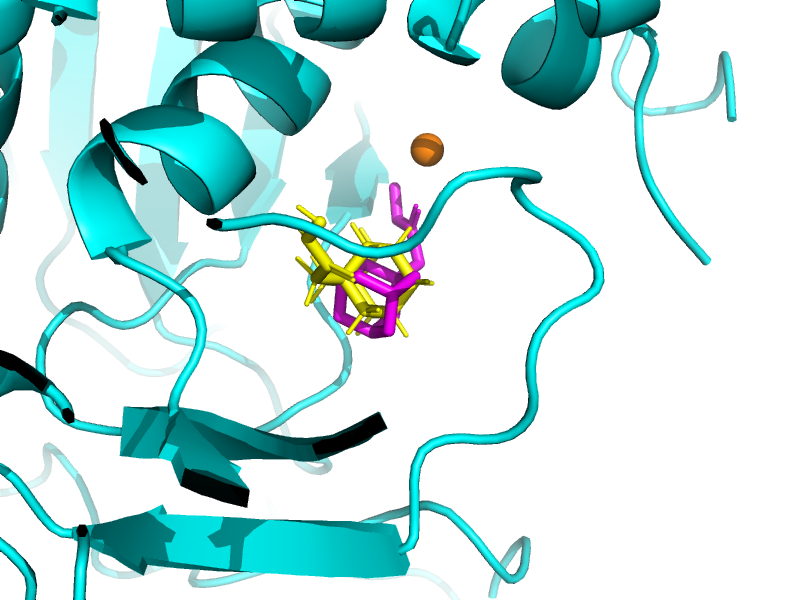

In [2]:
import pymol2
from IPython.display import Image, display

pymol_png = f"{example_dir}/receptor_binding_site.png"
with pymol2.PyMOL() as pymol:
    pymol.cmd.load(apo_receptor_pdb, "receptor")
    pymol.cmd.load(crystal_sdf, "crystal_ligand")
    pymol.cmd.load(docked_sdf, "vina_first_pose")
    pymol.cmd.zoom("vina_first_pose", buffer=6)
    pymol.cmd.show("sticks", "crystal_ligand")
    pymol.cmd.color("cyan", "receptor")
    pymol.cmd.color("magenta", "crystal_ligand")
    pymol.cmd.color("yellow", "vina_first_pose")
    pymol.cmd.set("sphere_scale", 0.5)
    pymol.cmd.set("sphere_color", "orange")
    pymol.cmd.turn("y", 180)
    pymol.cmd.png(pymol_png, width=800, height=600, ray=1)
display(Image(filename=pymol_png))

## Running CHELATE

`predict_poses` does the whole inference path in one call: it reads the receptor and the docked poses, detects the metal centre, computes the contact features around it, and predicts a metal-binding-group (MBG) RMSD for every pose.

Note that no crystal structure is involved — this is exactly what you would run on a real target.

In [3]:
result = predict_poses(
    receptor=apo_receptor_pdb,
    poses=docked_sdf,
    method="VINA",
)

print(f"Detected metals: {result.metals}")
print(f"Scored {len(result.poses)} poses")
print(
    f"Predicted MBG RMSD range: "
    f"{result.features['chelate_prediction'].min():.3f} - "
    f"{result.features['chelate_prediction'].max():.3f} A"
)

# reranked() drops the poses the model does not trust and leaves the rest in Vina's
# own order; see section 2. Sort by chelate_prediction instead to inspect the
# predictions themselves.
result.features.sort_values("chelate_prediction")[
    ["pose", "docking_score", "chelate_prediction"]
].head(10)

Detected metals: ['Zn']
Scored 96 poses
Predicted MBG RMSD range: 0.627 - 2.257 A


,pose,docking_score,chelate_prediction
4,5,-6.428,0.626649
9,10,-6.349,0.688429
7,8,-6.376,0.701278
57,58,-5.534,0.760432
16,17,-6.097,0.817010
19,20,-6.017,0.869349
29,30,-5.843,0.897528
25,26,-5.910,0.904473
23,24,-5.919,0.914167
31,32,-5.813,0.934118


## Filtering

CHELATE re-ranks by *filtering*, not by scoring: it discards the poses whose predicted MBG RMSD exceeds the cutoff (by default the paper's operating point for the docking program, `chelate.DEFAULT_CUTOFFS`: 0.80 Å for Vina, 0.85 Å for smina, 0.90 Å for GNINA, chosen on the validation set), and Vina's own `docking_score` then ranks whatever survives. So the prediction decides which poses are eligible, and the docking program still decides the order among them. (For GNINA the ranking column is `CNNscore`, where higher is better.)

`baseline_top1()` is what Vina alone would have returned, for comparison.

In [4]:
# The package default for Vina poses, the operating point used throughout the paper.
CUTOFF = result.default_cutoff

survivors = result.reranked(cutoff=CUTOFF)
top1_chelate = result.top1(cutoff=CUTOFF)
top1_vina = result.baseline_top1()

print(
    f"Poses passing the {CUTOFF:.2f} A filter: {len(survivors)} / {len(result.poses)}"
)
print()
print(
    f"Vina top-1     - pose {int(top1_vina['pose']):3d} | "
    f"docking_score={top1_vina['docking_score']:7.3f} | "
    f"predicted={top1_vina['chelate_prediction']:.3f} A"
)
if top1_chelate is not None:
    print(
        f"CHELATE top-1  - pose {int(top1_chelate['pose']):3d} | "
        f"docking_score={top1_chelate['docking_score']:7.3f} | "
        f"predicted={top1_chelate['chelate_prediction']:.3f} A"
    )
else:
    print(f"CHELATE top-1  - no pose passed the {CUTOFF:.2f} A filter")

survivors[["pose", "docking_score", "chelate_prediction"]]

Poses passing the 0.80 A filter: 4 / 96

Vina top-1     - pose   1 | docking_score= -6.886 | predicted=1.447 A
CHELATE top-1  - pose   5 | docking_score= -6.428 | predicted=0.627 A


,pose,docking_score,chelate_prediction
4,5,-6.428,0.626649
7,8,-6.376,0.701278
9,10,-6.349,0.688429
57,58,-5.534,0.760432


## CHELATE Predictions

Everything above ran without a reference structure. Since this example *has* a crystal pose, we can check the predictions against it — this is benchmarking, not something available on a real target.

The reference MBG uses the original holo metal coordinates in `crystal_reference.json`. The apo metal moves enough to select a different group, so its coordinates must not define these benchmark labels. This reference is used only to evaluate predictions.

In [5]:
import json
from pathlib import Path

reference_metals = json.loads(
    Path(f"{example_dir}/crystal_reference.json").read_text()
)["metal_coords"]
result.add_reference_mbg_rmsd(crystal_sdf, reference_metal_coords=reference_metals)

,ab_3.5,ab_3.5_mean,ab_3.5_min,ab_3.5_max,ab_3.5_std,ab_4.5,ab_4.5_mean,ab_4.5_min,ab_4.5_max,ab_4.5_std,...,has_Cu,has_Mg,has_Zn,has_Fe,has_Ni,has_Ca,has_Na,has_GenericMetal,chelate_prediction,reference_mbg_rmsd
0,10.0,3.263668,2.887458,3.459265,0.167127,86.0,3.992815,2.887458,4.489135,0.385577,...,0,0,1,0,0,0,0,0,1.446533,8.365134
1,8.0,3.299966,2.929564,3.441257,0.164014,88.0,4.012239,2.929564,4.488250,0.361531,...,0,0,1,0,0,0,0,0,1.547513,8.413813
2,14.0,3.310264,2.996636,3.487293,0.133062,82.0,3.954177,2.996636,4.495741,0.383698,...,0,0,1,0,0,0,0,0,1.433255,8.695006
3,15.0,3.295199,2.881472,3.496850,0.189944,81.0,3.951176,2.881472,4.495338,0.402769,...,0,0,1,0,0,0,0,0,1.420875,8.703330
4,14.0,3.187824,2.810638,3.496484,0.188487,84.0,3.894943,2.810638,4.497000,0.423412,...,0,0,1,0,0,0,0,0,0.626649,0.705664
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,10.0,3.251496,2.903468,3.479637,0.182411,44.0,3.903122,2.903468,4.496370,0.452667,...,0,0,1,0,0,0,0,0,2.120222,7.843393
92,13.0,3.245294,2.981265,3.497779,0.168458,55.0,3.877204,2.981265,4.481500,0.441797,...,0,0,1,0,0,0,0,0,1.073836,0.485984
93,12.0,3.267079,2.777302,3.483397,0.189719,53.0,3.881220,2.777302,4.464427,0.411818,...,0,0,1,0,0,0,0,0,2.024198,4.078133
94,5.0,3.178369,2.973453,3.493054,0.236630,51.0,3.965402,2.973453,4.491077,0.389467,...,0,0,1,0,0,0,0,0,2.155722,6.604838


In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(
    result.features["reference_mbg_rmsd"],
    result.features["chelate_prediction"],
    alpha=0.6,
    s=20,
    color="steelblue",
)
ax.axvline(CUTOFF, color="tomato", lw=1.2, ls="--", label=f"{CUTOFF:.2f} A cutoff")
ax.axhline(CUTOFF, color="tomato", lw=1.2, ls="--")
ax.set_xlabel("True MBG RMSD to crystal pose (A)", fontsize=12)
ax.set_ylabel("Predicted MBG RMSD (A)", fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

print(
    f"Vina top-1    true MBG RMSD: {result.features.loc[top1_vina.name, 'reference_mbg_rmsd']:.3f} A"
)
if top1_chelate is not None:
    print(
        f"CHELATE top-1 true MBG RMSD: {result.features.loc[top1_chelate.name, 'reference_mbg_rmsd']:.3f} A"
    )

Vina top-1    true MBG RMSD: 8.365 A
CHELATE top-1 true MBG RMSD: 0.706 A


You can see that the CHELATE predictions closely cluster around the 1 Å MBG RMSD threshold, even though the true MBG RMSD can be much larger. This is because the model was trained to improve the MBG RMSD Success rate, defined by the 1 Å threshold, meaning assignment of a larger MBG RMSD does not improve the model during training.

Finally, let's visualise the top-1 pose before and after filtering.

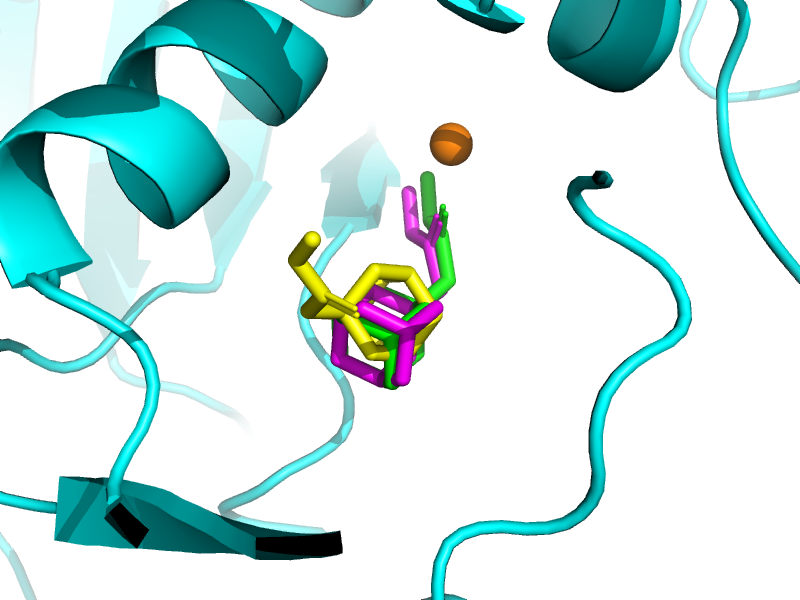

In [7]:
unfilt_sdf = f"{example_dir}/top1_unfiltered.sdf"
result.write_sdf(unfilt_sdf, top1_vina)

filt_sdf = None
if top1_chelate is not None:
    filt_sdf = f"{example_dir}/top1_filtered.sdf"
    result.write_sdf(filt_sdf, top1_chelate)

comparison_png = f"{example_dir}/chelate_top1_comparison.png"
with pymol2.PyMOL() as pymol:
    pymol.cmd.load(apo_receptor_pdb, "receptor")
    pymol.cmd.load(crystal_sdf, "crystal")
    pymol.cmd.load(unfilt_sdf, "top1_unfiltered")
    if filt_sdf:
        pymol.cmd.load(filt_sdf, "top1_filtered")

    pymol.cmd.color("cyan", "receptor")
    pymol.cmd.color("magenta", "crystal")
    pymol.cmd.color("yellow", "top1_unfiltered")
    if filt_sdf:
        pymol.cmd.color("green", "top1_filtered")

    shown = "crystal or top1_unfiltered" + (" or top1_filtered" if filt_sdf else "")
    pymol.cmd.show("sticks", shown)
    pymol.cmd.zoom("crystal", buffer=6)
    pymol.cmd.set("sphere_scale", 0.5)
    pymol.cmd.set("sphere_color", "orange")
    pymol.cmd.turn("y", 180)
    pymol.cmd.png(comparison_png, width=800, height=600, ray=1)
display(Image(filename=comparison_png))